In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

## Load Experiment

First, we load the experiment from the `results` folder. Each experiment is collected into a single `.parquet` file. Its rows contain recognition results for each configuration (combination) and each fold (flattened).

In [2]:
# Configuration which experiment should be loaded.
EXPERIMENT_NAME = "arcface_fusion_levels"
RESULTS_PATH = Path("../../results")

In [3]:
# Load the experiment dataset.
EXPERIMENT_PATH = RESULTS_PATH / f"{EXPERIMENT_NAME}.parquet"
EXPERIMENT_DATA = pd.read_parquet(EXPERIMENT_PATH)
EXPERIMENT_DATA

,identity,video,observations,top-1,top-5,top-10,predicted,fold,gallery_frame_anonymization,gallery_frame_aggregation,gallery_frame_embedding,gallery_embedding_aggregation,samples_frame_anonymization,samples_frame_aggregation,samples_frame_embedding,samples_embedding_aggregation,score_aggregation,pipeline
0,Aaron_Eckhart,2,56,0.946429,0.964286,0.982143,Aaron_Eckhart,1,none,video_none,arcface,video_none,none,video_none,arcface,video_none,max_none,frame
1,Abdel_Aziz_Al-Hakim,0,75,1.000000,1.000000,1.000000,Abdel_Aziz_Al-Hakim,1,none,video_none,arcface,video_none,none,video_none,arcface,video_none,max_none,frame
2,Abdullah_Gul,1,61,1.000000,1.000000,1.000000,Abdullah_Gul,1,none,video_none,arcface,video_none,none,video_none,arcface,video_none,max_none,frame
3,Abel_Pacheco,3,52,0.961538,0.980769,1.000000,Abel_Pacheco,1,none,video_none,arcface,video_none,none,video_none,arcface,video_none,max_none,frame
4,Adam_Sandler,0,48,1.000000,1.000000,1.000000,Adam_Sandler,1,none,video_none,arcface,video_none,none,video_none,arcface,video_none,max_none,frame
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45403,Yuri_Fedotov,4,49,0.000000,0.000000,0.000000,Choi_Sung-hong,3,none,video_none,arcface,identity_pooling_mean,pixelation,video_none,arcface,video_none,max_max,frame
45404,Zhang_Ziyi,1,75,0.000000,0.000000,0.000000,Choi_Sung-hong,3,none,video_none,arcface,identity_pooling_mean,pixelation,video_none,arcface,video_none,max_max,frame
45405,Zhong_Nanshan,5,75,0.000000,1.000000,1.000000,Choi_Sung-hong,3,none,video_none,arcface,identity_pooling_mean,pixelation,video_none,arcface,video_none,max_max,frame
45406,Zoran_Djindjic,2,75,0.000000,1.000000,1.000000,Choi_Sung-hong,3,none,video_none,arcface,identity_pooling_mean,pixelation,video_none,arcface,video_none,max_max,frame


## Visualize accuracy

The following plots show the mean accuracy for each combination of (sample) anonymization method and (gallery) aggregation method. The anonymization method is only applied to the samples. The gallery uses clear frames.

The first plot aggregates the predictions based on their confidence before classifying. The latter does not and instead takes the mean accuracy over all single-frame classifications.

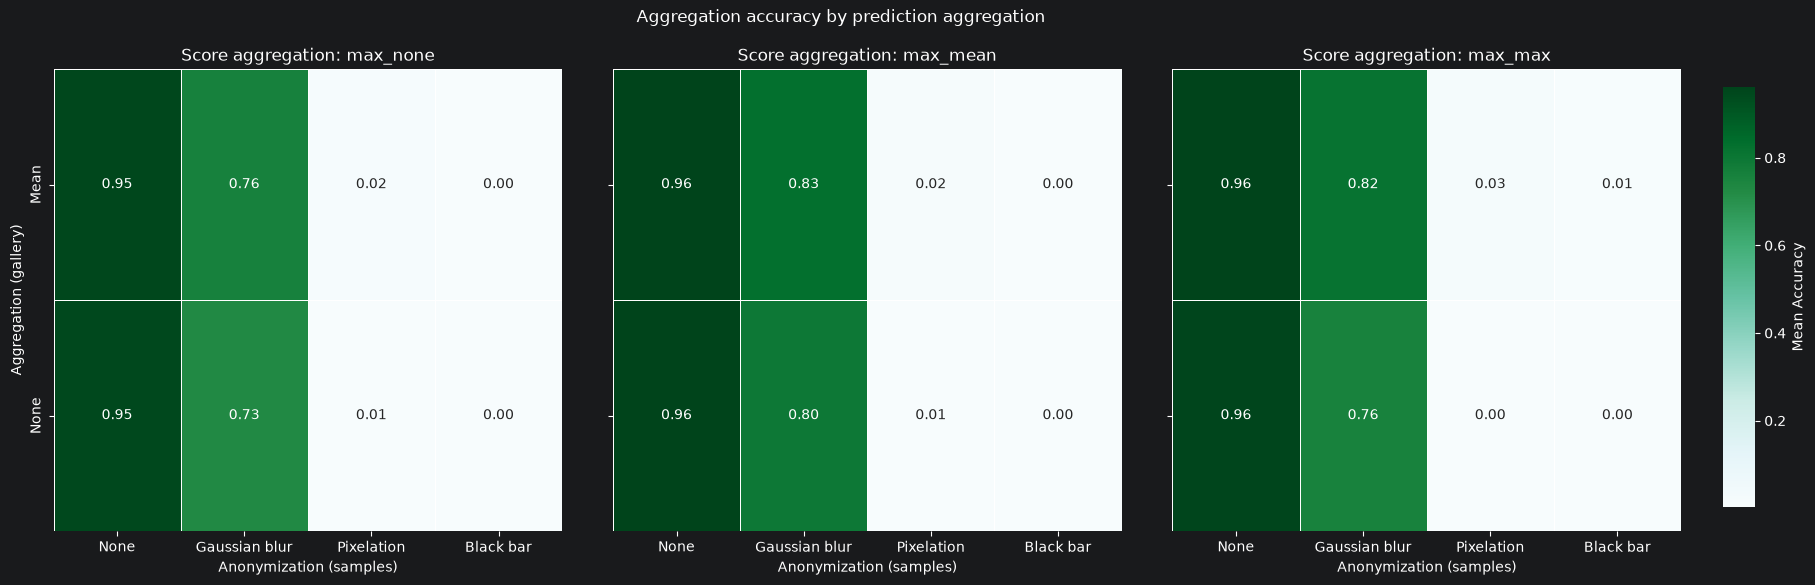

In [12]:
# Rename labels once, on the full dataset
data = EXPERIMENT_DATA.replace(
    {
        "samples_frame_anonymization": {
            "none": "None",
            "gaussianblur": "Gaussian blur",
            "blackbar": "Black bar",
            "pixelation": "Pixelation",
        },
        "gallery_embedding_aggregation": {
            "video_none": "None",
            "identity_pooling_mean": "Mean",
            "identity_consensus_beta1": "Consensus (beta=1)",
            "identity_normweighted": "Norm weighted",
        },
    }
)
METRIC = "top-1"

# Shared ordering across all panels
agg_order = data.groupby("gallery_embedding_aggregation")[METRIC].mean().sort_values(ascending=False).index
embedding_order = data.groupby("samples_frame_anonymization")[METRIC].mean().sort_values(ascending=False).index

score_aggs = data["score_aggregation"].unique()  # or a fixed list, e.g. ["max_mean", ...]

# Build all pivots first so we can find a shared color range
pivots = {
    s: data[data["score_aggregation"] == s]
    .pivot_table(
        index="gallery_embedding_aggregation",
        columns="samples_frame_anonymization",
        values=METRIC,
        aggfunc="mean",
    )
    .reindex(index=agg_order, columns=embedding_order)
    for s in score_aggs
}
vmin = min(p.min().min() for p in pivots.values())
vmax = max(p.max().max() for p in pivots.values())

fig, axes = plt.subplots(1, len(score_aggs), figsize=(7 * len(score_aggs), 6), sharey=True)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # one colorbar for all panels

for i, (ax, s) in enumerate(zip(axes, score_aggs)):
    sns.heatmap(
        pivots[s],
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="BuGn",
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="w",
        cbar=(i == 0),
        cbar_ax=cbar_ax if i == 0 else None,
        cbar_kws={"label": "Mean Accuracy"},
    )
    ax.set_title(f"Score aggregation: {s}")
    ax.set_xlabel("Anonymization (samples)")
    ax.set_ylabel("Aggregation (gallery)" if i == 0 else "")

fig.suptitle("Aggregation accuracy by prediction aggregation")
fig.subplots_adjust(right=0.9, wspace=0.1)
plt.show()